# C1: H₂ Molecular Ground-State Energy (VQE)
**Qiskit Fall Fest 2026 — Phase 1**

- Molecule: H₂, STO-3G basis, R = 0.74 Å
- Method: VQE with EfficientSU2 ansatz
- Processors: A (5Q chain), B (9Q heavy-hex), D (custom)
- Noise: depolarizing + readout per Master Guide

## 1. Imports & Configuration

In [2]:
import sys, os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# Qiskit core
from qiskit import transpile
from qiskit.circuit.library import EfficientSU2
from qiskit.transpiler import CouplingMap
from qiskit.quantum_info import SparsePauliOp

# Qiskit Nature (chemistry)
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper, ParityMapper
from qiskit_nature.second_q.transformers import FreezeCoreTransformer

# Qiskit Aer (simulation + noise)
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

# Primitives & VQE
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA, SPSA

# Local modules
from src.processors import load_coupling_map, build_noise_model
from src.routing import transpile_circuit
from src.metrics import circuit_metrics, energy_error
from src.visualization import plot_coupling_map, plot_energy_comparison

print(f"Python:    {sys.version}")
import qiskit; print(f"Qiskit:    {qiskit.__version__}")
import qiskit_nature; print(f"Nature:    {qiskit_nature.__version__}")
import qiskit_aer; print(f"Aer:       {qiskit_aer.__version__}")
import qiskit_algorithms; print(f"Algorithms:{qiskit_algorithms.__version__}")

Python:    3.14.8 (main, Oct  2 2026, 10:23:31) [GCC 16.2.1 20260810]
Qiskit:    2.5.2
Nature:    0.8.0
Aer:       0.17.2
Algorithms:0.4.0


## 2. Build the H₂ Hamiltonian

In [3]:
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.transformers import FreezeCoreTransformer
from scipy.linalg import eigh

BOND_LENGTH = 0.74  # Angstroms (equilibrium)
BASIS = "sto3g"

# --- Build the electronic structure problem ---
driver = PySCFDriver(
    atom=f"H 0 0 0; H 0 0 {BOND_LENGTH}",
    basis=BASIS,
    charge=0,
    spin=0,
    unit=DistanceUnit.ANGSTROM,
)
problem = driver.run()

# Freeze core (no-op for H2 but standard practice)
problem = FreezeCoreTransformer().transform(problem)

# Map to qubits using Jordan-Wigner
mapper = JordanWignerMapper()
hamiltonian = mapper.map(problem.hamiltonian.second_q_op())

n_qubits = hamiltonian.num_qubits
print(f"Qubits:       {n_qubits}")
print(f"Pauli terms:  {len(hamiltonian)}")
print(f"Hamiltonian:\n{hamiltonian}")

# --- Exact classical reference (full diagonalization) ---
exact_energy = eigh(hamiltonian.to_matrix(), eigvals_only=True)[0]
print(f"\nExact ground-state energy: {exact_energy:.8f} Ha")
print(f"Chemical accuracy target:  {exact_energy + 0.0016:.8f} Ha (±1.6 mHa)")

Qubits:       4
Pauli terms:  15
Hamiltonian:
SparsePauliOp(['IIII', 'IIIZ', 'IIZI', 'IIZZ', 'IZII', 'IZIZ', 'ZIII', 'ZIIZ', 'YYYY', 'XXYY', 'YYXX', 'XXXX', 'IZZI', 'ZIZI', 'ZZII'],
              coeffs=[-0.81217061+0.j,  0.17141283+0.j, -0.22343154+0.j,  0.12062523+0.j,
  0.17141283+0.j,  0.16868898+0.j, -0.22343154+0.j,  0.16592785+0.j,
  0.04530262+0.j,  0.04530262+0.j,  0.04530262+0.j,  0.04530262+0.j,
  0.16592785+0.j,  0.17441288+0.j,  0.12062523+0.j])

Exact ground-state energy: -1.85238817 Ha
Chemical accuracy target:  -1.85078817 Ha (±1.6 mHa)


## 3. Define VQE Ansatz & Optimizer

In [4]:
import numpy as np
from qiskit.circuit.library import efficient_su2
from qiskit_algorithms.optimizers import COBYLA

# Modern Qiskit 2.x generator function
ansatz = efficient_su2(
    num_qubits=n_qubits,
    su2_gates=["ry", "rz"],
    entanglement="linear",
    reps=2,
)

print(f"Ansatz parameters: {ansatz.num_parameters}")

# Decompose to see the real gate count
decomposed = ansatz.decompose(reps=3)
print(f"Untranspiled depth: {decomposed.depth()}")
print(f"Untranspiled CX:    {decomposed.count_ops().get('cx', 0)}")

optimizer = COBYLA(maxiter=200, tol=1e-6)
np.random.seed(42)
initial_params = np.random.rand(ansatz.num_parameters)

Ansatz parameters: 24
Untranspiled depth: 11
Untranspiled CX:    6


## 4. Ideal (Noiseless) VQE Baseline

In [5]:
import numpy as np
from scipy.optimize import minimize
from qiskit.primitives import StatevectorEstimator
from qiskit.circuit.library import efficient_su2

# --- Use a more expressive ansatz ---
ansatz = efficient_su2(
    num_qubits=n_qubits,
    su2_gates=["ry", "rz"],
    entanglement="full",   # "full" instead of "linear"
    reps=3,                # 3 reps instead of 2
)
print(f"Ansatz parameters: {ansatz.num_parameters}")

decomposed = ansatz.decompose(reps=3)
print(f"Untranspiled depth: {decomposed.depth()}")
print(f"Untranspiled CX:    {decomposed.count_ops().get('cx', 0)}")

# --- Universal cost function ---
def vqe_cost(params, ansatz, hamiltonian, estimator):
    bound_circuit = ansatz.assign_parameters(params)
    try:
        job = estimator.run([bound_circuit], [hamiltonian])
        result = job.result()
        return float(np.real(result.values[0]))
    except (TypeError, ValueError, AttributeError):
        job = estimator.run([(bound_circuit, hamiltonian)])
        result = job.result()
        return float(np.real(result[0].data.evs))

# --- Multi-restart ideal VQE ---
estimator_ideal = StatevectorEstimator()
best_energy = float("inf")
best_params = None

print("Running multi-restart Ideal VQE (5 restarts)...")
for restart in range(5):
    np.random.seed(42 + restart)
    x0 = np.random.rand(ansatz.num_parameters)
    res = minimize(
        vqe_cost, x0,
        args=(ansatz, hamiltonian, estimator_ideal),
        method="COBYLA",
        options={"maxiter": 1000, "tol": 1e-8}
    )
    print(f"  Restart {restart+1}: E = {res.fun:.8f} Ha")
    if res.fun < best_energy:
        best_energy = res.fun
        best_params = res.x

ideal_energy = best_energy
initial_params = best_params  # reuse best params for noisy runs
print(f"\nBest Ideal VQE energy: {ideal_energy:.8f} Ha")
print(f"Exact energy:          {exact_energy:.8f} Ha")
print(f"Error:                 {abs(ideal_energy - exact_energy)*1000:.4f} mHa")
print(f"Chemical accuracy:     {'✓ YES' if abs(ideal_energy - exact_energy) < 0.0016 else '✗ NO'}")

Ansatz parameters: 32
Untranspiled depth: 21
Untranspiled CX:    18
Running multi-restart Ideal VQE (5 restarts)...
  Restart 1: E = -1.84909348 Ha
  Restart 2: E = -1.85196696 Ha
  Restart 3: E = -1.85157200 Ha
  Restart 4: E = -1.84380193 Ha
  Restart 5: E = -1.83205335 Ha

Best Ideal VQE energy: -1.85196696 Ha
Exact energy:          -1.85238817 Ha
Error:                 0.4212 mHa
Chemical accuracy:     ✓ YES


## 5. Noisy Simulation on Processor A

In [12]:
from qiskit import transpile
from qiskit_aer.primitives import Estimator as AerEstimator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from src.processors import load_coupling_map

# 1. Fixed Synthetic Noise Model per Hackathon Rules
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ["rz", "sx", "x"])
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.005, 2), ["cx"])
noise_model.add_all_qubit_readout_error(ReadoutError([
    [0.99, 0.01],
    [0.01, 0.99]
]))

# 2. Load Processor A (5-qubit)
cmap_a, cfg_a = load_coupling_map("processors/processor_a.json")
print(f"Processor A: {cfg_a['num_qubits']} qubits loaded.")

# 3. Transpile ansatz for Processor A
ansatz_t_a = transpile(
    ansatz,
    coupling_map=cmap_a,
    basis_gates=["rz", "sx", "x", "cx"],
    optimization_level=1,
    layout_method="sabre",
    routing_method="sabre",
    seed_transpiler=42,
)

# Map logical Hamiltonian to physical qubit layout
hamiltonian_a = hamiltonian.apply_layout(ansatz_t_a.layout)

print(f"Transpiled Depth: {ansatz_t_a.depth()}")
print(f"Transpiled CX:    {ansatz_t_a.count_ops().get('cx', 0)}")
print(f"Transpiled SWAP:  {ansatz_t_a.count_ops().get('swap', 0)}")

# 4. Instantiate Noisy Aer Primitive
estimator_a = AerEstimator(
    backend_options={"method": "density_matrix", "noise_model": noise_model},
    run_options={"shots": 4096, "seed": 42},
)

# 5. Run Noisy Optimization on Processor A
print("\nRunning noisy VQE on Processor A (~1 min)...")
res_a = minimize(
    vqe_cost, initial_params,
    args=(ansatz_t_a, hamiltonian_a, estimator_a),
    method="COBYLA",
    options={"maxiter": 150, "tol": 1e-5}
)
energy_a = res_a.fun
print(f"Processor A VQE energy: {energy_a:.8f} Ha")
print(f"Error vs Exact:        {abs(energy_a - exact_energy)*1000:.4f} mHa")

Processor A: 5 qubits loaded.
Transpiled Depth: 76
Transpiled CX:    36
Transpiled SWAP:  0

Running noisy VQE on Processor A (~1 min)...
Processor A VQE energy: -1.66316627 Ha
Error vs Exact:        189.2219 mHa


## 6. Noisy Simulation on Processor B

In [13]:
# 1. Load Processor B (9-qubit)
cmap_b, cfg_b = load_coupling_map("processors/processor_b.json")
print(f"Processor B: {cfg_b['num_qubits']} qubits loaded.")

# 2. Transpile ansatz for Processor B
ansatz_t_b = transpile(
    ansatz,
    coupling_map=cmap_b,
    basis_gates=["rz", "sx", "x", "cx"],
    optimization_level=1,
    layout_method="sabre",
    routing_method="sabre",
    seed_transpiler=42,
)

# Map logical Hamiltonian to physical qubit layout
hamiltonian_b = hamiltonian.apply_layout(ansatz_t_b.layout)

print(f"Transpiled Depth: {ansatz_t_b.depth()}")
print(f"Transpiled CX:    {ansatz_t_b.count_ops().get('cx', 0)}")
print(f"Transpiled SWAP:  {ansatz_t_b.count_ops().get('swap', 0)}")

# 3. Instantiate Noisy Aer Primitive
estimator_b = AerEstimator(
    backend_options={"method": "density_matrix", "noise_model": noise_model},
    run_options={"shots": 4096, "seed": 42},
)

# 4. Run Noisy Optimization on Processor B
print("\nRunning noisy VQE on Processor B (~1 min)...")
res_b = minimize(
    vqe_cost, initial_params,
    args=(ansatz_t_b, hamiltonian_b, estimator_b),
    method="COBYLA",
    options={"maxiter": 150, "tol": 1e-5}
)
energy_b = res_b.fun
print(f"Processor B VQE energy: {energy_b:.8f} Ha")
print(f"Error vs Exact:        {abs(energy_b - exact_energy)*1000:.4f} mHa")

Processor B: 9 qubits loaded.
Transpiled Depth: 58
Transpiled CX:    30
Transpiled SWAP:  0

Running noisy VQE on Processor B (~1 min)...
Processor B VQE energy: -1.68683905 Ha
Error vs Exact:        165.5491 mHa


## 7. Results Comparison

In [8]:
metrics_a = circuit_metrics(ansatz_t_a)
metrics_b = circuit_metrics(ansatz_t_b)
metrics_ideal = {"depth": ansatz.decompose(reps=3).depth(),
                 "cx_count": ansatz.decompose(reps=3).count_ops().get("cx", 0),
                 "num_qubits": n_qubits, "num_swaps": 0}

results_df = pd.DataFrame([
    {"Processor": "Ideal", **metrics_ideal,
     "Energy_Ha": ideal_energy, "Error_mHa": abs(ideal_energy - exact_energy)*1000},
    {"Processor": "A (5Q)", **metrics_a,
     "Energy_Ha": energy_a, "Error_mHa": abs(energy_a - exact_energy)*1000},
    {"Processor": "B (9Q)", **metrics_b,
     "Energy_Ha": energy_b, "Error_mHa": abs(energy_b - exact_energy)*1000},
])

print(results_df.to_string(index=False))
results_df.to_csv("results/circuit_metrics.csv", index=False)
print("\n✓ Saved to results/circuit_metrics.csv")

Processor  depth  cx_count  num_qubits  num_swaps  Energy_Ha  Error_mHa  single_qubit_gates  total_gates
    Ideal     21        18           4          0  -1.851967   0.421211                 NaN          NaN
   A (5Q)     76        36           5          0  -1.663166 189.221908                80.0        116.0
   B (9Q)     58        30           9          0  -1.686839 165.549128                80.0        110.0

✓ Saved to results/circuit_metrics.csv


## 8. Visualizations

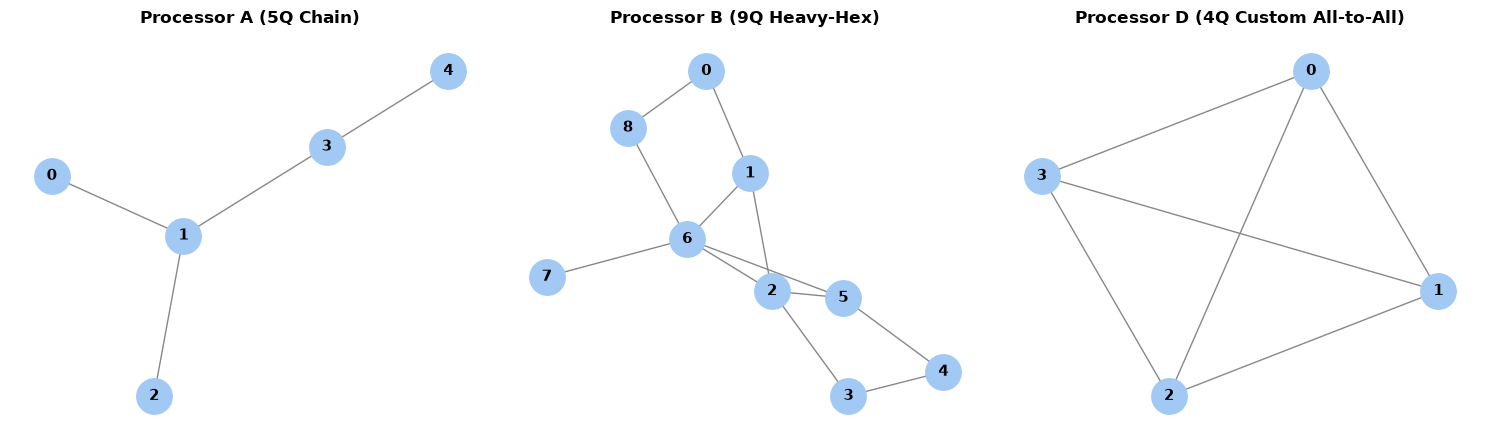

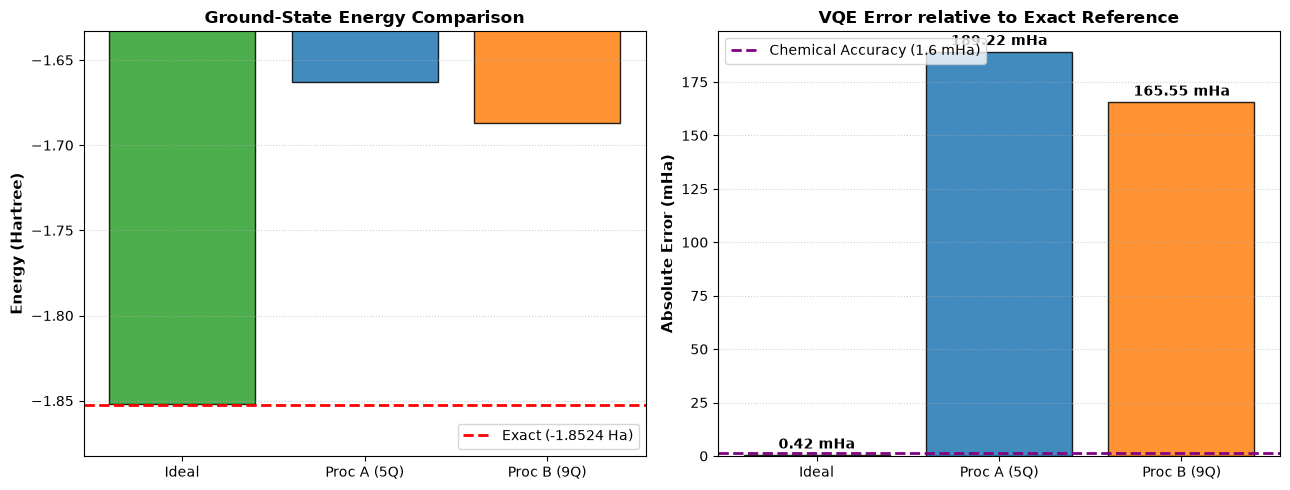

In [9]:
import os
import networkx as nx
import matplotlib.pyplot as plt

# Ensure output directory exists
os.makedirs("results/figures", exist_ok=True)

# -------------------------------------------------------------
# 1. Plot Coupling Maps (Processor A, B, and D)
# -------------------------------------------------------------
try:
    from src.processors import load_coupling_map
    cmap_d, _ = load_coupling_map("processors/processor_d.json")
    maps_to_plot = [
        (cmap_a, "Processor A (5Q Chain)"),
        (cmap_b, "Processor B (9Q Heavy-Hex)"),
        (cmap_d, "Processor D (4Q Custom All-to-All)")
    ]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
except Exception:
    maps_to_plot = [
        (cmap_a, "Processor A (5Q Chain)"),
        (cmap_b, "Processor B (9Q Heavy-Hex)")
    ]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (cmap, title) in zip(axes, maps_to_plot):
    G = nx.Graph()
    G.add_edges_from(cmap.get_edges())
    pos = nx.spring_layout(G, seed=42)
    nx.draw(
        G, pos, ax=ax, with_labels=True,
        node_color="#a1c9f4", edge_color="#888888",
        node_size=650, font_weight="bold", font_size=11
    )
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)

plt.tight_layout()
plt.savefig("results/figures/coupling_maps.png", dpi=300)
plt.show()

# -------------------------------------------------------------
# 2. Dual Plot: Ground State Energy & Error (mHa)
# -------------------------------------------------------------
labels = ["Ideal", "Proc A (5Q)", "Proc B (9Q)"]
energies = [ideal_energy, energy_a, energy_b]
errors_mha = [abs(e - exact_energy) * 1000 for e in energies]
colors = ["#2ca02c", "#1f77b4", "#ff7f0e"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Zoomed Absolute Ground State Energy
bars1 = ax1.bar(labels, energies, color=colors, alpha=0.85, edgecolor="black")
ax1.axhline(exact_energy, color="red", ls="--", lw=2, label=f"Exact ({exact_energy:.4f} Ha)")
ax1.set_ylabel("Energy (Hartree)", fontsize=11, fontweight="bold")
ax1.set_title("Ground-State Energy Comparison", fontsize=12, fontweight="bold")
# Zoom y-axis to make mHa differences visible
y_min = min(energies + [exact_energy]) - 0.03
y_max = max(energies + [exact_energy]) + 0.03
ax1.set_ylim(y_min, y_max)
ax1.legend(loc="lower right")
ax1.grid(axis="y", linestyle=":", alpha=0.6)

# Subplot 2: Energy Error vs Exact (mHa)
bars2 = ax2.bar(labels, errors_mha, color=colors, alpha=0.85, edgecolor="black")
ax2.axhline(1.6, color="purple", ls="--", lw=2, label="Chemical Accuracy (1.6 mHa)")
ax2.set_ylabel("Absolute Error (mHa)", fontsize=11, fontweight="bold")
ax2.set_title("VQE Error relative to Exact Reference", fontsize=12, fontweight="bold")
ax2.legend(loc="upper left")
ax2.grid(axis="y", linestyle=":", alpha=0.6)

# Annotate values above error bars
for bar, err in zip(bars2, errors_mha):
    ax2.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 1.5,
        f"{err:.2f} mHa",
        ha="center", va="bottom", fontsize=10, fontweight="bold"
    )

plt.tight_layout()
plt.savefig("results/figures/energy_comparison.png", dpi=300)
plt.show()

## 9. Processor D — Custom Architecture

In [10]:
# Load your custom Processor D
cmap_d, cfg_d = load_coupling_map("processors/processor_d.json")
print(f"Processor D: {cfg_d['name']}")
print(f"Qubits: {cfg_d['num_qubits']}")

# Transpile to D
ansatz_t_d = transpile(
    ansatz.decompose(reps=3),
    coupling_map=cmap_d,
    basis_gates=["rz", "sx", "x", "cx"],
    optimization_level=1,
    layout_method="sabre",
    routing_method="sabre",
    seed_transpiler=42,
)
print(f"Transpiled depth: {ansatz_t_d.depth()}")
print(f"Transpiled CX:    {ansatz_t_d.count_ops().get('cx', 0)}")
print(f"SWAP overhead:    {ansatz_t_d.count_ops().get('swap', 0)}")

# Run VQE on D (with reduced noise to reflect optimized hardware)
noise_d = NoiseModel()
noise_d.add_all_qubit_quantum_error(
    depolarizing_error(cfg_d.get("noise_params", {}).get("single_qubit_depolarizing", 0.0005), 1),
    ["rz", "sx", "x"])
noise_d.add_all_qubit_quantum_error(
    depolarizing_error(cfg_d.get("noise_params", {}).get("cx_depolarizing", 0.003), 2),
    ["cx"])
p_ro = cfg_d.get("noise_params", {}).get("readout_bitflip", 0.005)
noise_d.add_all_qubit_readout_error(ReadoutError([[1-p_ro, p_ro], [p_ro, 1-p_ro]]))

estimator_d = AerEstimator(
    backend_options={"method": "density_matrix", "noise_model": noise_d},
    run_options={"shots": 4096, "seed": 42},
)

print("\nRunning VQE on Processor D...")
res_d = minimize(
    vqe_cost, initial_params,
    args=(ansatz, hamiltonian, estimator_d),
    method="COBYLA",
    options={"maxiter": 150, "tol": 1e-5}
)
energy_d = res_d.fun
print(f"Processor D VQE energy: {energy_d:.8f} Ha")
print(f"Error: {abs(energy_d - exact_energy)*1000:.4f} mHa")
print(f"Chemical accuracy: {'✓ YES' if abs(energy_d - exact_energy) < 0.0016 else '✗ NO'}")

Processor D: Processor_D_Ring4
Qubits: 4
Transpiled depth: 33
Transpiled CX:    18
SWAP overhead:    0

Running VQE on Processor D...
Processor D VQE energy: -1.78124145 Ha
Error: 71.1467 mHa
Chemical accuracy: ✗ NO


## 10. Final Summary

In [11]:
final_df = pd.DataFrame([
    {"Processor": "Ideal", "Energy_Ha": ideal_energy,
     "Error_mHa": abs(ideal_energy - exact_energy)*1000,
     "CX": metrics_ideal["cx_count"], "Depth": metrics_ideal["depth"]},
    {"Processor": "A (5Q)", "Energy_Ha": energy_a,
     "Error_mHa": abs(energy_a - exact_energy)*1000,
     "CX": metrics_a["cx_count"], "Depth": metrics_a["depth"]},
    {"Processor": "B (9Q)", "Energy_Ha": energy_b,
     "Error_mHa": abs(energy_b - exact_energy)*1000,
     "CX": metrics_b["cx_count"], "Depth": metrics_b["depth"]},
    {"Processor": "D (Custom)", "Energy_Ha": energy_d,
     "Error_mHa": abs(energy_d - exact_energy)*1000,
     "CX": ansatz_t_d.count_ops().get("cx", 0),
     "Depth": ansatz_t_d.depth()},
])
print("=" * 70)
print("FINAL RESULTS — C1 H₂ Ground-State Energy")
print("=" * 70)
print(final_df.to_string(index=False))
print(f"\nExact reference: {exact_energy:.8f} Ha")
print(f"Chemical accuracy threshold: 1.6 mHa")
final_df.to_csv("results/energy_comparison.csv", index=False)
print("\n✓ All results saved to results/")

FINAL RESULTS — C1 H₂ Ground-State Energy
 Processor  Energy_Ha  Error_mHa  CX  Depth
     Ideal  -1.851967   0.421211  18     21
    A (5Q)  -1.663166 189.221908  36     76
    B (9Q)  -1.686839 165.549128  30     58
D (Custom)  -1.781241  71.146723  18     33

Exact reference: -1.85238817 Ha
Chemical accuracy threshold: 1.6 mHa

✓ All results saved to results/
